<a href="https://colab.research.google.com/github/jaywong8/Detection-of-Atrial-Fibrillation-Termination/blob/src/SingleRecordExample.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Downloading and accessing one record from icentia11k

In [ ]:

!pip -q install wfdb

from pathlib import Path
import urllib.request
import wfdb
import matplotlib.pyplot as plt

# Define the record and local folder
record_name = "p00060_s00"
data_dir = Path("/content/icentia_sample")
data_dir.mkdir(parents=True, exist_ok=True)

# Official PhysioNet directory
base_url = (
    "https://physionet.org/files/"
    "icentia11k-continuous-ecg/1.0/p00/p00060/"
)

# Download only missing files
for ext in ["hea", "dat", "atr"]:
    filename = f"{record_name}.{ext}"
    filepath = data_dir / filename

    if not filepath.exists():
        url = base_url + filename
        urllib.request.urlretrieve(url, filepath)

    print(f"Ready: {filepath.name} ({filepath.stat().st_size:,} bytes)")

# Define the WFDB record prefix
record_path = str(data_dir / record_name)

print("\nSetup complete.")
print("Record path:", record_path)


Ready: p00060_s00.hea (86 bytes)
Ready: p00060_s00.dat (2,097,154 bytes)
Ready: p00060_s00.atr (48,764 bytes)

Setup complete.
Record path: /content/icentia_sample/p00060_s00


Initializing variables to reference points of annotation and records

Episode table columns: ['start_sec', 'end_sec', 'duration_sec', 'status']


,start_sec,end_sec,duration_sec,status
0,3.27,5.62,2.35,Annotated interval; outcome unverified
1,29.80,40.72,10.92,Annotated interval; outcome unverified
2,200.78,208.55,7.77,Annotated interval; outcome unverified
3,234.52,263.46,28.94,Annotated interval; outcome unverified
4,302.76,309.18,6.42,Annotated interval; outcome unverified



Number of extracted AFib intervals: 59

Duration summary (seconds):


,duration_sec
count,59.000000
mean,26.782881
std,54.193838
min,2.350000
25%,7.625000
50%,10.920000
75%,25.045000
90%,49.494000
95%,67.240000
max,364.360000



Intervals at least as long as each threshold:
 10 seconds:  33 / 59 (55.9%)
 30 seconds:  10 / 59 (16.9%)
 60 seconds:   4 / 59 (6.8%)
300 seconds:   1 / 59 (1.7%)


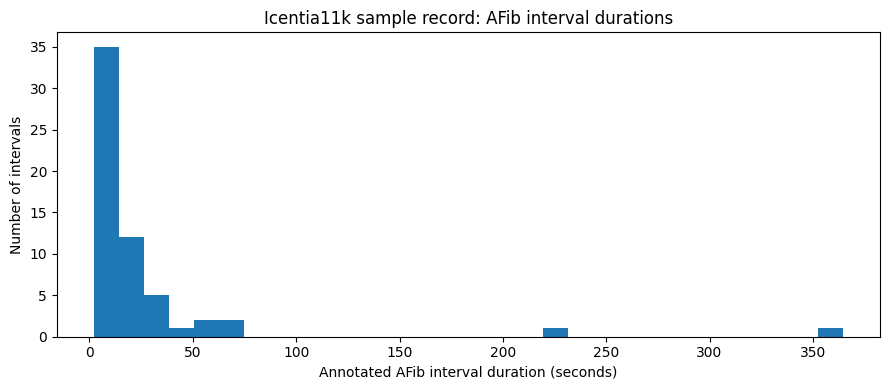


First 40 non-empty rhythm annotation entries:
     3.27s | (AFIB
     5.62s | )
    29.80s | (AFIB
    40.72s | )
   200.78s | (AFIB
   208.55s | )
   234.52s | (AFIB
   263.46s | )
   302.76s | (AFIB
   309.18s | )
   450.26s | (AFIB
   461.86s | )
   574.32s | (AFIB
   938.69s | )
   961.49s | (AFIB
   982.99s | )
  1065.92s | (AFIB
  1072.96s | )
  1078.53s | (AFIB
  1108.99s | )
  1121.35s | (AFIB
  1127.82s | )
  1137.72s | (AFIB
  1144.30s | )
  1156.32s | (AFIB
  1170.36s | )
  1178.33s | (AFIB
  1186.00s | )
  1194.61s | (AFIB
  1201.80s | )
  1230.30s | (AFIB
  1238.50s | )
  1271.60s | (AFIB
  1493.43s | )
  1538.88s | (AFIB
  1589.63s | )
  1631.13s | (AFIB
  1646.57s | )
  1761.78s | (AFIB
  1783.58s | )
  1789.04s | (AFIB
  1804.61s | )
  1810.33s | (AFIB
  1836.32s | )
  1841.88s | (AFIB
  1854.22s | )
  1928.52s | (AFIB
  1938.18s | )
  1943.34s | (AFIB
  1952.34s | )
  1957.18s | (AFIB
  1988.43s | )
  1995.48s | (AFIB
  2021.78s | )
  2157.19s | (AFIB
  2163.20s | )
 

In [ ]:

import wfdb
import numpy as np
import matplotlib.pyplot as plt

# Reload the complete sample record from the files already downloaded.
record = wfdb.rdrecord(record_path)
ann = wfdb.rdann(record_path, "atr")

fs = record.fs
signal = record.p_signal[:, 0]

print(f"Sampling rate: {fs} Hz")
print(f"Record duration: {len(signal) / fs / 60:.2f} minutes")
print(f"Signal samples: {len(signal):,}")

# Rebuild AFib intervals from the current record's annotations.
events = []
for sample, note in zip(ann.sample, ann.aux_note):
    if note is not None and str(note).strip():
        note = str(note).strip()
        if note.lower() != "none":
            events.append((int(sample), note))

events.sort(key=lambda x: x[0])

regions = []
for i, (start, note) in enumerate(events):
    if not note.upper().startswith("(AFIB"):
        continue

    # Find the next closing marker or rhythm-start marker.
    for end_sample, end_note in events[i + 1:]:
        if end_note == ")" or end_note.startswith("("):
            if end_sample > start:
                regions.append({
                    "rhythm": "AFib",
                    "start": start,
                    "end": end_sample
                })
            break
# Inspect the annotation sequence around each extracted AFib interval.
# Uses the existing `ann`, `record`, and `episodes_df` variables.

events = []

for sample, note in zip(ann.sample, ann.aux_note):
    note = note.strip() if note else ""
    if note:
        events.append((int(sample), note))

print("First 15 AFib intervals with neighboring rhythm annotations:\n")

shown = 0

for i, (sample, note) in enumerate(events):
    if not note.upper().startswith("(AFIB"):
        continue

    # Find the next closing marker or rhythm-start marker
    end_idx = None
    for j in range(i + 1, len(events)):
        if events[j][1] == ")" or events[j][1].startswith("("):
            end_idx = j
            break

    start_time = sample / record.fs

    print(f"AFIB starts at {start_time:.2f}s: {note}")

    if i > 0:
        print("  Previous annotation:", events[i - 1][1])

    if end_idx is not None:
        end_sample, end_note = events[end_idx]
        print(
            f"  Next boundary: {end_note} "
            f"at {end_sample / record.fs:.2f}s"
        )
        if end_idx + 1 < len(events):
            print("  Following annotation:", events[end_idx + 1][1])
    else:
        print("  No subsequent rhythm boundary found.")

    print()
    shown += 1

    if shown >= 15:
        break


Loading and identifying annotated segments

In [ ]:

# Load all annotations for this record
ann = wfdb.rdann(record_path, "atr")

print("Total annotations:", len(ann.sample))
print("\nAnnotations containing rhythm labels:\n")

for sample, note in zip(ann.sample, ann.aux_note):
    note = note.strip() if note else ""

    if note:
        print(f"{sample / record.fs:9.2f} sec | {note}")


Total annotations: 6090

Annotations containing rhythm labels:

     0.26 sec | None
     1.13 sec | None
     2.06 sec | None
     2.68 sec | None
     3.27 sec | None
     3.27 sec | (AFIB
     3.94 sec | None
     4.81 sec | None
     5.62 sec | None
     5.62 sec | )
     6.16 sec | None
     6.66 sec | None
     7.27 sec | None
     7.83 sec | None
     8.53 sec | None
     9.10 sec | None
     9.61 sec | None
    10.22 sec | None
    11.00 sec | None
    11.68 sec | None
    12.67 sec | None
    13.20 sec | None
    14.13 sec | None
    14.56 sec | None
    15.30 sec | None
    16.24 sec | None
    17.32 sec | None
    17.84 sec | None
    18.51 sec | None
    19.44 sec | None
    20.16 sec | None
    20.89 sec | None
    21.47 sec | None
    22.09 sec | None
    22.84 sec | None
    23.39 sec | None
    24.01 sec | None
    24.80 sec | None
    25.44 sec | None
    25.77 sec | None
    26.12 sec | None
    26.75 sec | None
    27.26 sec | None
    27.96 sec | None
    28.39 sec 

Visualizing afib intervals

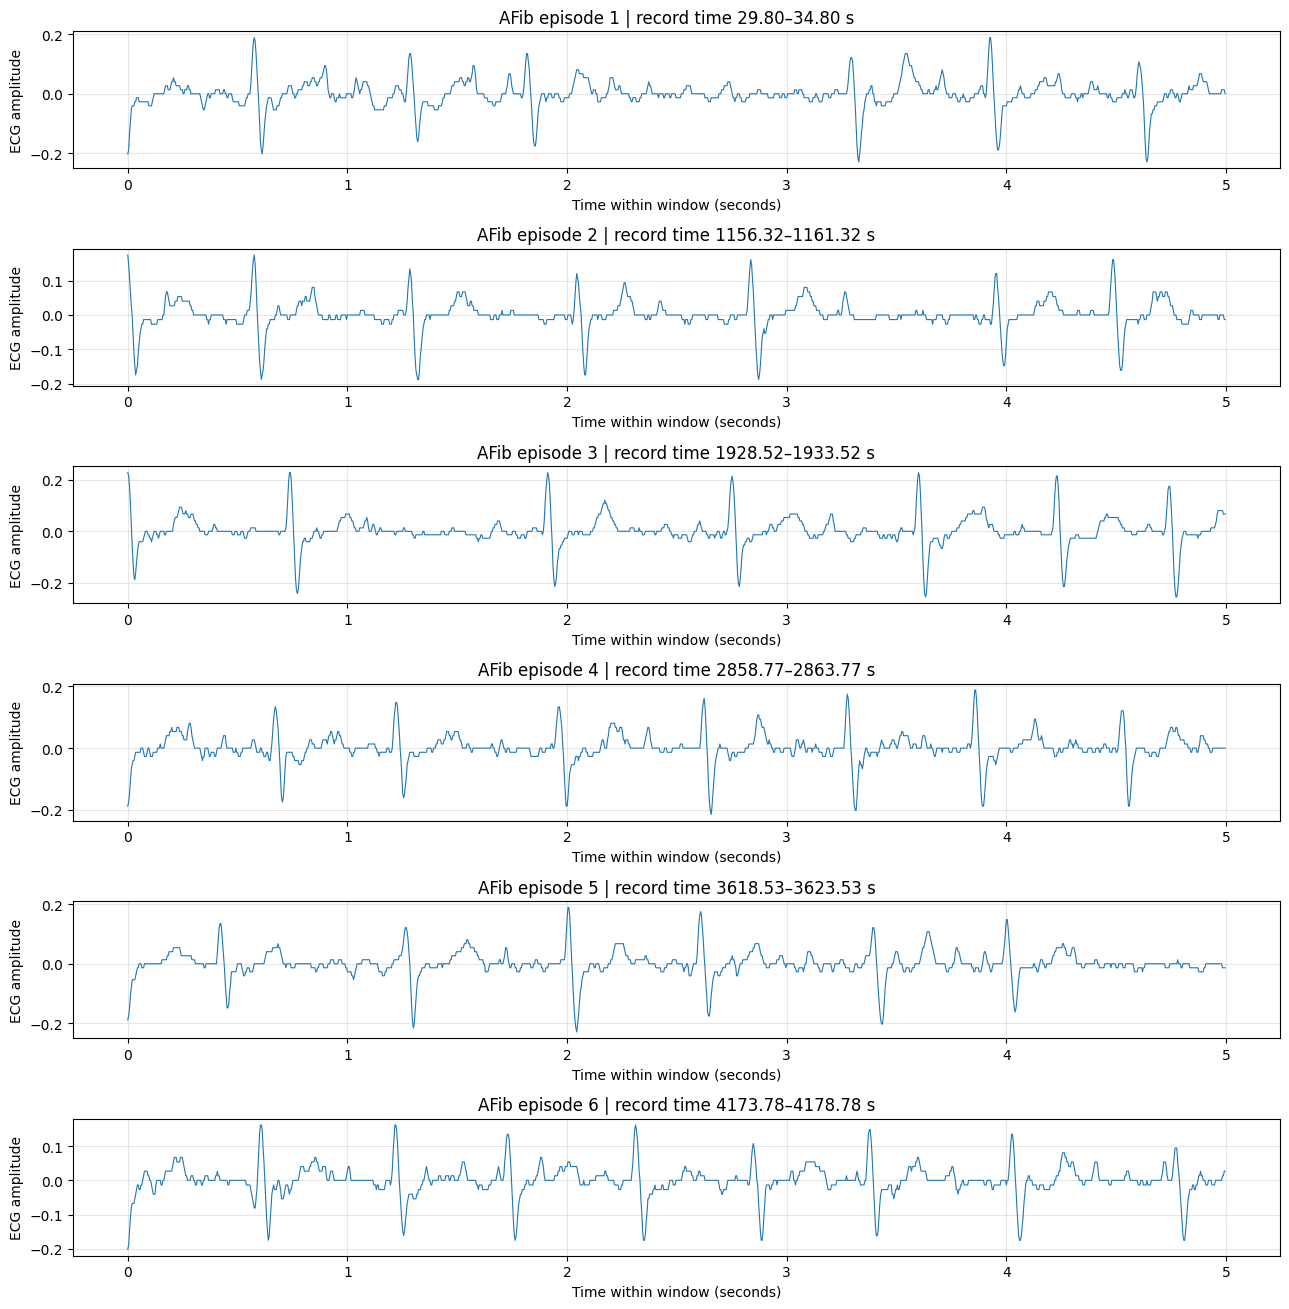

In [ ]:

# Select multiple AFib intervals with at least 5 seconds available.
window_samples = int(5 * fs)

afib_regions = [
    r for r in regions
    if r["end"] - r["start"] >= window_samples
]

if not afib_regions:
    raise ValueError("No AFib intervals long enough for a 5-second plot.")

# Choose how many AFib windows to display.
num_windows = min(6, len(afib_regions))

# Select evenly spaced episodes across the recording.
selected_indices = np.linspace(
    0, len(afib_regions) - 1,
    num=num_windows,
    dtype=int
)

selected_regions = [afib_regions[i] for i in selected_indices]

# Plot each selected AFib window.
fig, axes = plt.subplots(
    num_windows, 1,
    figsize=(13, 2.2 * num_windows),
    squeeze=False
)

for i, (ax, region) in enumerate(zip(axes[:, 0], selected_regions)):
    start = region["start"]
    end = start + window_samples

    segment = signal[start:end]
    t = np.arange(len(segment)) / fs

    ax.plot(t, segment, linewidth=0.8)
    ax.set_title(
        f"AFib episode {i + 1} | "
        f"record time {start / fs:.2f}–{end / fs:.2f} s"
    )
    ax.set_xlabel("Time within window (seconds)")
    ax.set_ylabel("ECG amplitude")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


Counting annotation types --> nothing other than afib, may want to look at other records for normal sinus rhytm

In [ ]:
from collections import Counter

rhythm_notes = [
    str(note).strip()
    for note in ann.aux_note
    if note is not None
    and str(note).strip()
    and str(note).strip().lower() != "none"
]

print("All non-empty annotation notes:")
print(Counter(rhythm_notes))

print("\nExplicit normal-rhythm starts:")
print(sum(note.startswith("(N") for note in rhythm_notes))

print("Explicit AFib starts:")
print(sum(note.startswith("(AFIB") for note in rhythm_notes))

print("Explicit flutter starts:")
print(sum(note.startswith("(AFL") for note in rhythm_notes))

All non-empty annotation notes:
Counter({'(AFIB': 59, ')': 59})

Explicit normal-rhythm starts:
0
Explicit AFib starts:
59
Explicit flutter starts:
0


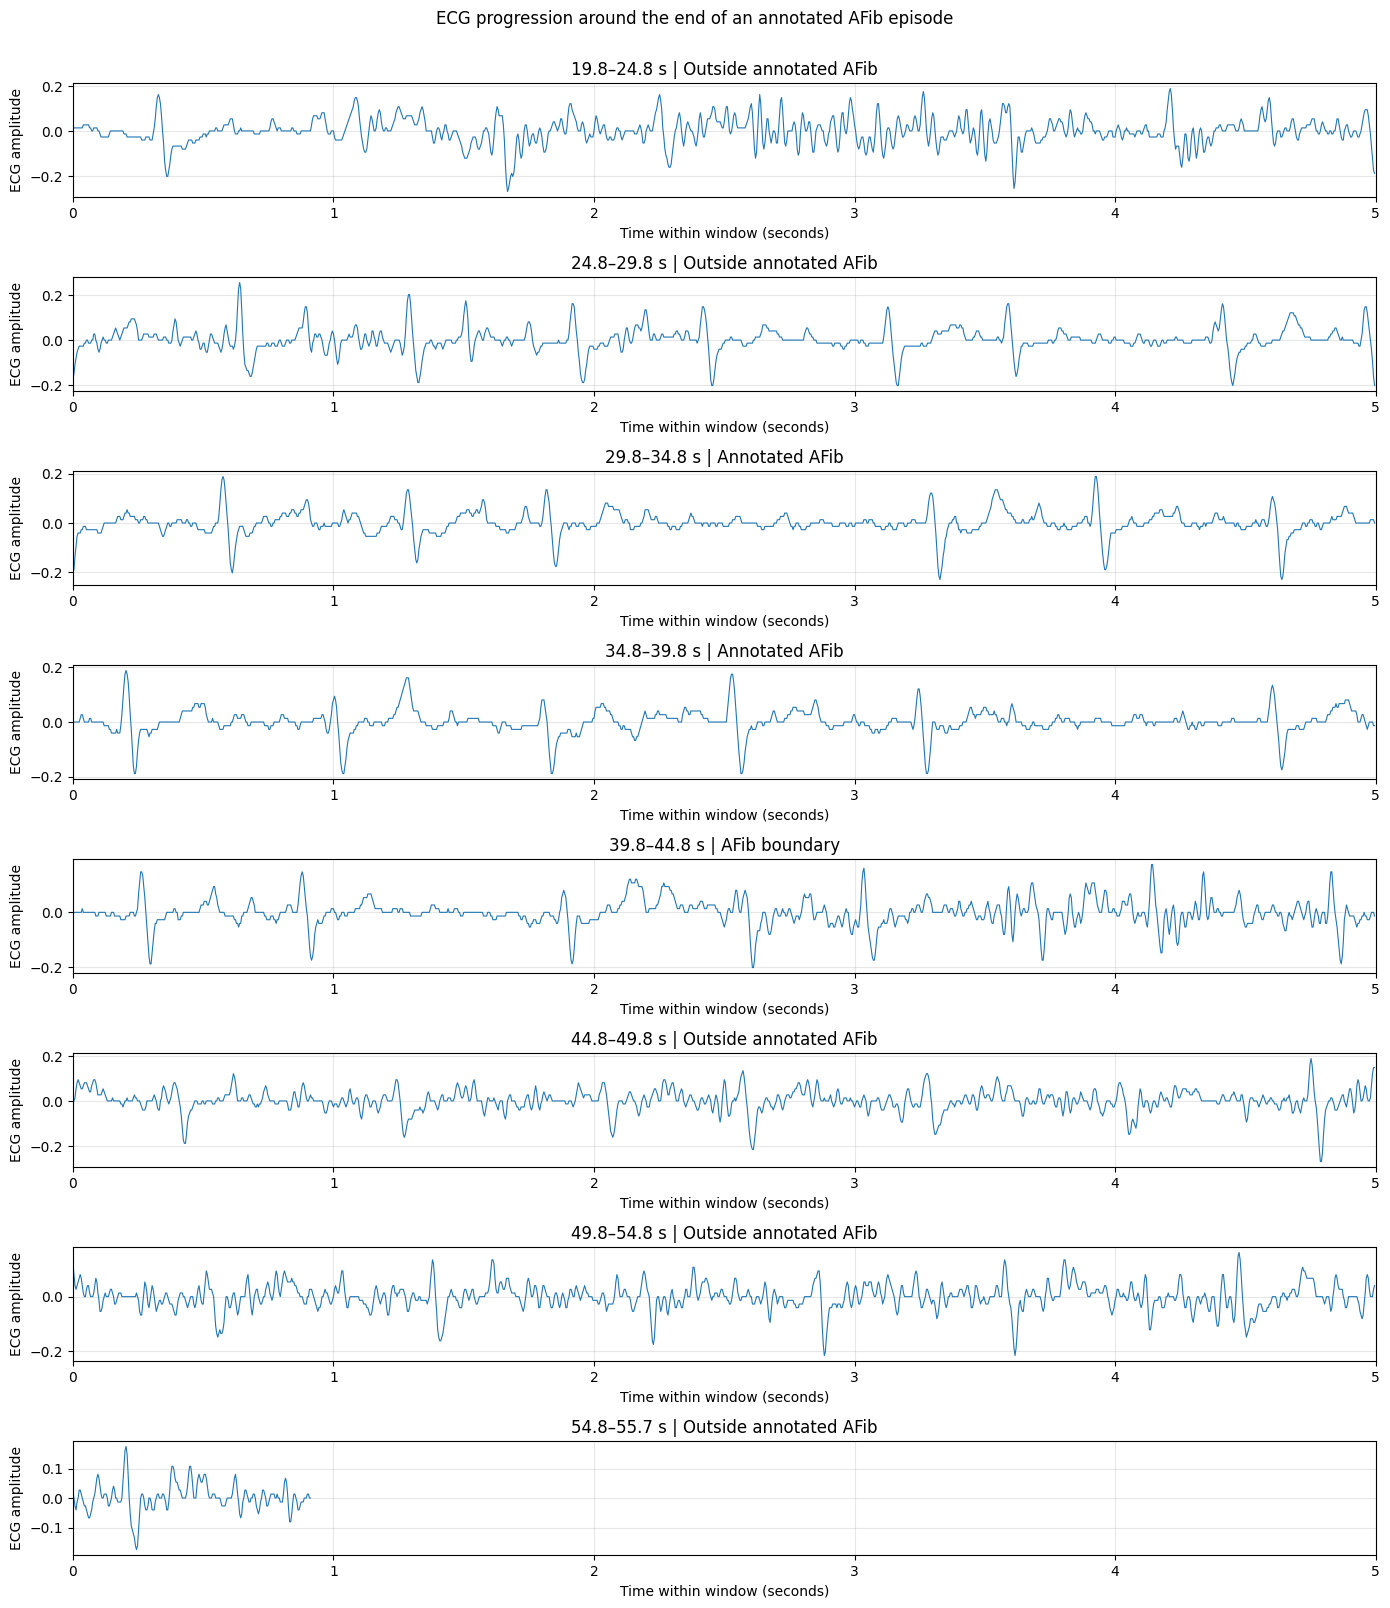

AFib start: 29.80 s
AFib end:   40.72 s
Number of 5-second windows: 8


In [ ]:

# Find an AFib episode followed by at least 15 seconds
# outside the extracted AFib intervals.

interval_seconds = 5
before_seconds = 10
after_seconds = 15

candidates = sorted(regions, key=lambda r: r["start"])
chosen = None

for i, r in enumerate(candidates):
    duration = (r["end"] - r["start"]) / fs

    if not (10 <= duration <= 60):
        continue

    next_start = (
        candidates[i + 1]["start"]
        if i + 1 < len(candidates)
        else len(signal)
    )

    if (
        r["start"] >= before_seconds * fs
        and (next_start - r["end"]) / fs >= after_seconds
    ):
        chosen = r
        break

if chosen is None:
    raise ValueError(
        "No suitable AFib episode found. Try another record."
    )

af_start = chosen["start"]
af_end = chosen["end"]

# Create consecutive 5-second windows centered around the
# AFib episode's ending, including 10 seconds before it.
plot_start = int(af_start - before_seconds * fs)
plot_end = min(len(signal), int(af_end + after_seconds * fs))

window_samples = int(interval_seconds * fs)

# Generate consecutive, non-overlapping 5-second windows.
windows = [
    (start, min(start + window_samples, plot_end))
    for start in range(plot_start, plot_end, window_samples)
]

fig, axes = plt.subplots(
    len(windows), 1,
    figsize=(14, 2.0 * len(windows)),
    squeeze=False
)

for i, (ax, (start, end)) in enumerate(zip(axes[:, 0], windows)):
    segment = signal[start:end]
    t = np.arange(len(segment)) / fs

    ax.plot(t, segment, linewidth=0.8)

    # Determine whether this window overlaps the annotated AFib interval.
    overlaps_afib = start < af_end and end > af_start

    if start >= af_start and end <= af_end:
        label = "Annotated AFib"
    elif overlaps_afib:
        label = "AFib boundary"
    else:
        label = "Outside annotated AFib"

    ax.set_title(
        f"{start / fs:.1f}–{end / fs:.1f} s | {label}"
    )
    ax.set_xlabel("Time within window (seconds)")
    ax.set_ylabel("ECG amplitude")
    ax.set_xlim(0, interval_seconds)
    ax.grid(True, alpha=0.3)

plt.suptitle(
    "ECG progression around the end of an annotated AFib episode",
    y=1.002
)
plt.tight_layout()
plt.show()

print(f"AFib start: {af_start / fs:.2f} s")
print(f"AFib end:   {af_end / fs:.2f} s")
print(f"Number of 5-second windows: {len(windows)}")


In [ ]:

# Find an explicitly annotated AFib -> normal sinus rhythm transition.
'''
events = sorted(
    [
        (int(sample), str(note).strip())
        for sample, note in zip(ann.sample, ann.aux_note)
        if note is not None
        and str(note).strip()
        and str(note).strip().lower() != "none"
    ],
    key=lambda x: x[0]
)

transitions = []

for i, (af_start, note) in enumerate(events):
    if not note.startswith("(AFIB"):
        continue

    # Find the closing marker for this AFib region.
    close_idx = None

    for j in range(i + 1, len(events)):
        sample_j, note_j = events[j]

        if note_j == ")":
            close_idx = j
            break

        # Another rhythm starts before a closing marker.
        if note_j.startswith("("):
            break

    if close_idx is None:
        continue

    af_end = events[close_idx][0]

    # Find the next explicit rhythm-start annotation.
    next_rhythm = None

    for sample_j, note_j in events[close_idx + 1:]:
        if note_j.startswith("("):
            next_rhythm = (sample_j, note_j)
            break

    if next_rhythm is None:
        continue

    nsr_start, nsr_note = next_rhythm

    if nsr_note.startswith("(N") and nsr_start >= af_end:
        transitions.append({
            "af_start": af_start,
            "af_end": af_end,
            "nsr_start": nsr_start
        })

print("Explicit AFib-to-NSR transitions found:", len(transitions))

if transitions:
    # Choose the first candidate transition.
    transition = transitions[0]

    af_start = transition["af_start"]
    af_end = transition["af_end"]
    nsr_start = transition["nsr_start"]

    # Show up to 30 seconds before and after the NSR annotation.
    context_seconds = 30
    plot_start = max(0, nsr_start - int(context_seconds * fs))
    plot_end = min(len(signal), nsr_start + int(context_seconds * fs))

    t = np.arange(plot_start, plot_end) / fs
    segment = signal[plot_start:plot_end]

    plt.figure(figsize=(15, 4))
    plt.plot(t, segment, linewidth=0.6)

    # Mark the annotation boundaries.
    plt.axvline(
        af_start / fs, linestyle="--",
        label="AFib start"
    )
    plt.axvline(
        af_end / fs, linestyle=":",
        label="AFib closing marker"
    )
    plt.axvline(
        nsr_start / fs, linestyle="--",
        label="Annotated NSR start"
    )

    plt.xlabel("Time from start of recording (seconds)")
    plt.ylabel("ECG amplitude")
    plt.title("ECG around an annotated AFib-to-NSR transition")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

else:
    print(
        "No explicitly annotated AFib-to-NSR transition was found "
        "in this segment. Try another segment or patient."
    )
'''

Explicit AFib-to-NSR transitions found: 0
No explicitly annotated AFib-to-NSR transition was found in this segment. Try another segment or patient.


Attempted to depict afib intervals against non afib

Sampling rate: 250 Hz
Record duration: 69.91 minutes
Signal samples: 1,048,577
Selected gap: 0
Start time: 5.62 seconds
End time: 10.62 seconds


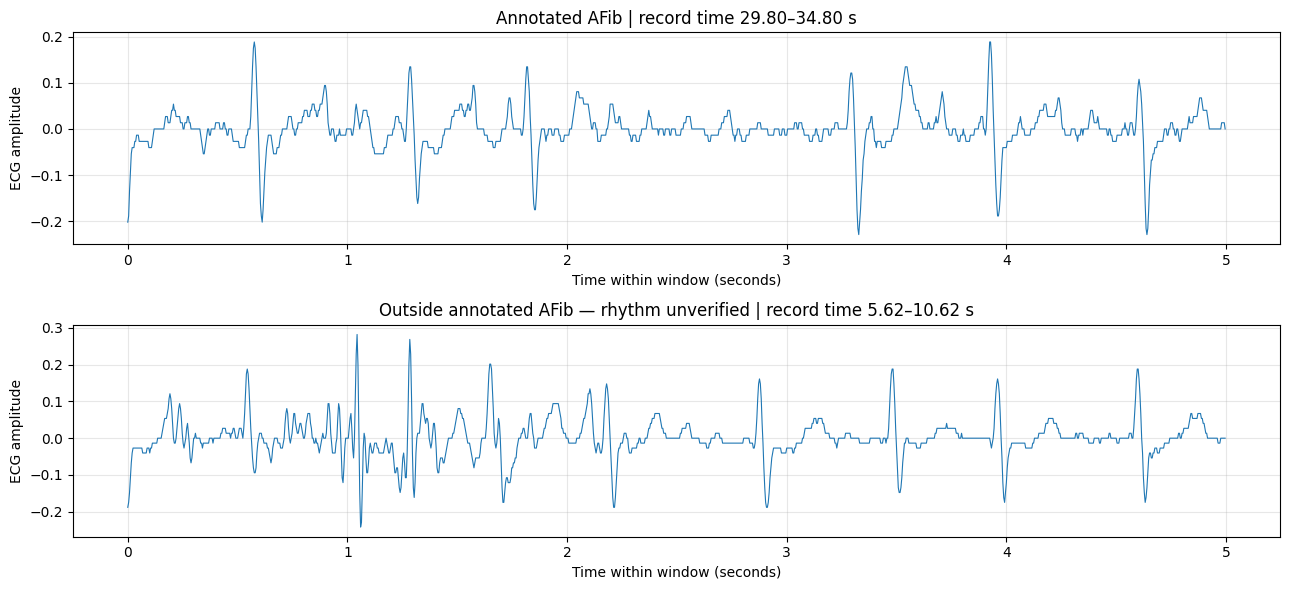

   0.26 s | None
   1.13 s | None
   2.06 s | None
   2.68 s | None
   3.27 s | None
   3.27 s | (AFIB
   3.94 s | None
   4.81 s | None
   5.62 s | None
   5.62 s | )
   6.16 s | None
   6.66 s | None
   7.27 s | None
   7.83 s | None
   8.53 s | None
   9.10 s | None
   9.61 s | None
  10.22 s | None
  11.00 s | None
  11.68 s | None
  12.67 s | None
  13.20 s | None
  14.13 s | None
  14.56 s | None
  15.30 s | None
  16.24 s | None
  17.32 s | None
  17.84 s | None
  18.51 s | None
  19.44 s | None
  20.16 s | None
  20.89 s | None
  21.47 s | None
  22.09 s | None
  22.84 s | None
  23.39 s | None
  24.01 s | None
  24.80 s | None
  25.44 s | None
  25.77 s | None
  26.12 s | None
  26.75 s | None
  27.26 s | None
  27.96 s | None
  28.39 s | None
  29.25 s | None
  29.80 s | None
  29.80 s | (AFIB
  30.41 s | None
  31.12 s | None
  31.65 s | None
  33.13 s | None
  33.73 s | None
  34.44 s | None
  35.04 s | None
  35.84 s | None
  36.64 s | None
  37.37 s | None
  38.08 s | Non

In [ ]:

import wfdb
import numpy as np
import matplotlib.pyplot as plt

# Reload the complete sample record from the files already downloaded.
record = wfdb.rdrecord(record_path)
ann = wfdb.rdann(record_path, "atr")

fs = record.fs
signal = record.p_signal[:, 0]

print(f"Sampling rate: {fs} Hz")
print(f"Record duration: {len(signal) / fs / 60:.2f} minutes")
print(f"Signal samples: {len(signal):,}")

# Rebuild AFib intervals from the current record's annotations.
events = []
for sample, note in zip(ann.sample, ann.aux_note):
    if note is not None and str(note).strip():
        note = str(note).strip()
        if note.lower() != "none":
            events.append((int(sample), note))

events.sort(key=lambda x: x[0])

regions = []
for i, (start, note) in enumerate(events):
    if not note.upper().startswith("(AFIB"):
        continue

    # Find the next closing marker or rhythm-start marker.
    for end_sample, end_note in events[i + 1:]:
        if end_note == ")" or end_note.startswith("("):
            if end_sample > start:
                regions.append({
                    "rhythm": "AFib",
                    "start": start,
                    "end": end_sample
                })
            break

# Pick one AFib interval with at least 5 seconds available.
window_samples = 5 * fs
afib_region = next(
    (r for r in regions if r["end"] - r["start"] >= window_samples),
    None
)

if afib_region is None:
    raise ValueError("No AFib interval long enough for a 5-second plot.")

af_start = afib_region["start"]
af_window = (af_start, af_start + window_samples)

# Find 5 seconds outside the extracted AFib intervals.
merged = []
for r in sorted(regions, key=lambda r: r["start"]):
    start = max(0, r["start"])
    end = min(len(signal), r["end"])
    if end <= start:
        continue
    if merged and start <= merged[-1][1]:
        merged[-1] = (merged[-1][0], max(merged[-1][1], end))
    else:
        merged.append((start, end))


# Find every 5-second gap outside the extracted AFib intervals.
non_af_windows = []
cursor = 0

for start, end in merged:
    if start - cursor >= window_samples:
        # Record the first 5 seconds of this gap.
        non_af_windows.append(
            (cursor, cursor + window_samples)
        )
    cursor = max(cursor, end)

# Check the gap after the final AFib interval.
if len(signal) - cursor >= window_samples:
    non_af_windows.append(
        (cursor, cursor + window_samples)
    )

if not non_af_windows:
    raise ValueError("No 5-second non-AFib interval found.")

# Choose which qualifying gap to inspect:
gap_index = 0  # 0 = first gap, 1 = second gap, 2 = third gap...

if gap_index >= len(non_af_windows):
    raise ValueError(
        f"Only {len(non_af_windows)} qualifying gaps found."
    )

non_af_window = non_af_windows[gap_index]

start_sample, end_sample = non_af_window

print("Selected gap:", gap_index)
print("Start time:", start_sample / 250, "seconds")
print("End time:", end_sample / 250, "seconds")


# Plot the two windows.
fig, axes = plt.subplots(2, 1, figsize=(13, 6))

for ax, (start, end), title in [
    (axes[0], af_window, "Annotated AFib"),
    (axes[1], non_af_window, "Outside annotated AFib — rhythm unverified")
]:
    segment = signal[start:end]
    t = np.arange(len(segment)) / fs
    ax.plot(t, segment, linewidth=0.8)
    ax.set_title(f"{title} | record time {start/fs:.2f}–{end/fs:.2f} s")
    ax.set_xlabel("Time within window (seconds)")
    ax.set_ylabel("ECG amplitude")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Inspect all non-empty rhythm annotations from 0–45 seconds
for sample, note in zip(ann.sample, ann.aux_note):
    if note is not None and str(note).strip():
        time_s = sample / record.fs
        if 0 <= time_s <= 45:
            print(f"{time_s:7.2f} s | {str(note).strip()}")

